# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [2]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


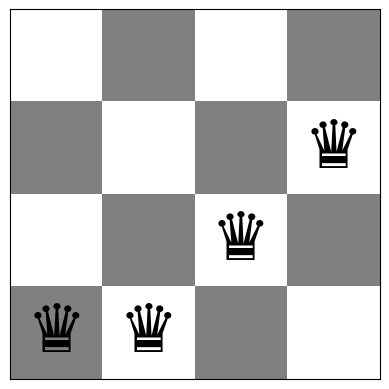

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [4]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


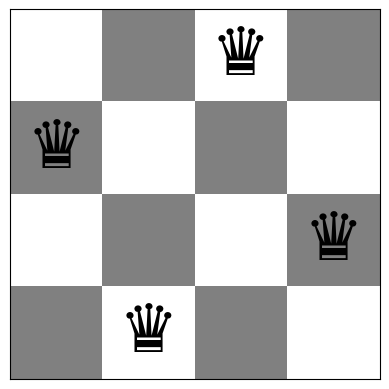

In [5]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

**Mô tả cài đặt.** Trạng thái là vector `board` (mỗi cột đúng một quân hậu). Lân cận = dời một quân hậu sang hàng khác trong cùng cột, tức $n(n-1)$ lân cận (12 với $n=4$, 56 với $n=8$). `f()` bọc `conflicts()` để đếm số lần đánh giá hàm mục tiêu.

In [6]:
# Code and description go here
import time, math
import numpy as np
import pandas as pd

# Đếm số lần gọi hàm mục tiêu: dùng để so sánh chi phí tính toán giữa các thuật toán.
eval_count = 0
def f(board):
    """Bọc conflicts() để đếm số lần đánh giá hàm mục tiêu."""
    global eval_count
    eval_count += 1
    return conflicts(board)

def run(algo, board, **kw):
    """Chạy một thuật toán, đo thời gian (ms), số lần đánh giá f và các chỉ số khác."""
    global eval_count
    eval_count = 0
    t0 = time.perf_counter()
    r = algo(board, **kw)
    r["time_ms"] = (time.perf_counter() - t0) * 1e3
    r["evals"] = eval_count
    return r

In [7]:
def steepest_ascent(board, max_iter=1000):
    """Task 1 - Steepest-ascent HC: xét TẤT CẢ n(n-1) lân cận, đi tới lân cận tốt nhất.
    Dừng khi không có lân cận nào có f nhỏ hơn hẳn (cực trị cục bộ) hoặc f = 0.
    Nếu nhiều lân cận cùng tốt nhất thì chọn ngẫu nhiên giữa chúng."""
    board = np.array(board).copy()
    n = len(board)
    current = f(board)
    hist = [current]                      # lịch sử f theo từng bước đi
    steps = 0
    while current > 0 and steps < max_iter:
        best_val, best_moves = current, []
        for col in range(n):              # mỗi cột: dời quân hậu sang hàng khác
            old = board[col]
            for row in range(n):
                if row == old: continue
                board[col] = row
                val = f(board)
                if val < best_val:                       # tốt hơn hẳn: làm mới danh sách
                    best_val, best_moves = val, [(col, row)]
                elif val == best_val and best_moves:     # hòa với ứng viên tốt nhất
                    best_moves.append((col, row))
            board[col] = old              # khôi phục trước khi xét cột kế tiếp
        if not best_moves:                # không còn nước cải thiện -> local optimum
            break
        col, row = best_moves[np.random.randint(len(best_moves))]
        board[col] = row
        current = best_val
        steps += 1
        hist.append(current)
    return dict(board=board, f=current, steps=steps, tries=steps, hist=hist)

# chạy thử trên một bàn cờ 8x8
np.random.seed(1234)
b0 = random_board(8)
r = steepest_ascent(b0)
print("Bàn cờ đầu :", b0, "-> f =", conflicts(b0))
print("Bàn cờ cuối:", r["board"], "-> f =", r["f"], "| số bước:", r["steps"], "| f theo bước:", r["hist"])


Bàn cờ đầu : [7 3 6 5 4 4 0 1] -> f = 9
Bàn cờ cuối: [7 3 7 2 4 6 0 5] -> f = 1 | số bước: 4 | f theo bước: [9, 6, 3, 2, 1]


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

**Mô tả cài đặt.** Giống Steepest-ascent về chi phí (vẫn đánh giá đủ $n(n-1)$ lân cận mỗi bước) nhưng chọn *ngẫu nhiên* trong tập các nước cải thiện thay vì chọn nước tốt nhất, nên đa dạng đường đi hơn nhưng thường cần nhiều bước hơn.

In [8]:
# Code and description go here
def stochastic_all_moves(board, max_iter=1000):
    """Task 2 - Inefficient Stochastic HC: liệt kê MỌI nước cải thiện (f giảm hẳn),
    rồi chọn ngẫu nhiên một nước. Chi phí mỗi bước vẫn là n(n-1) lần đánh giá."""
    board = np.array(board).copy()
    n = len(board)
    current = f(board)
    hist = [current]
    steps = 0
    while current > 0 and steps < max_iter:
        improving = []
        for col in range(n):
            old = board[col]
            for row in range(n):
                if row == old: continue
                board[col] = row
                val = f(board)
                if val < current:
                    improving.append((col, row, val))
            board[col] = old
        if not improving:                 # không có nước cải thiện -> local optimum
            break
        col, row, val = improving[np.random.randint(len(improving))]
        board[col] = row
        current = val
        steps += 1
        hist.append(current)
    return dict(board=board, f=current, steps=steps, tries=steps, hist=hist)

np.random.seed(1234)
r = stochastic_all_moves(random_board(8))
print("f cuối:", r["f"], "| số bước:", r["steps"], "| f theo bước:", r["hist"])


f cuối: 0 | số bước: 6 | f theo bước: [9, 6, 5, 4, 3, 2, 0]


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

**Mô tả cài đặt.** Mỗi vòng lặp chỉ sinh *một* lân cận ngẫu nhiên nên chi phí mỗi lần thử là 1 lần gọi `conflicts()` thay vì $n(n-1)$. Vì không bao giờ duyệt hết lân cận, ta phát hiện cực trị cục bộ bằng ngưỡng *x lần thử liên tiếp không cải thiện*, với $x = c \cdot N\ln N$, $N = n(n-1)$ (lấy mẫu có hoàn lại, bài toán coupon collector). Mặc định $c = 2$.

In [9]:
# Code and description go here
def stochastic_first_choice(board, patience_factor=2.0, max_tries=1_000_000):
    """Task 3 - Efficient Stochastic (First-choice) HC: mỗi lần chỉ sinh MỘT lân cận
    ngẫu nhiên (cột ngẫu nhiên, hàng mới ngẫu nhiên khác hàng hiện tại) và nhận nếu f giảm hẳn.
    Dừng khi f = 0, hoặc sau max_fail lần thử liên tiếp không cải thiện, hoặc hết max_tries.

    max_fail = ceil(patience_factor * N * ln N), với N = n(n-1) là số lân cận.
    Lý do: lấy mẫu CÓ hoàn lại trong N lân cận; xác suất bỏ sót một lân cận cụ thể sau
    x lần thử là (1 - 1/N)^x ~ exp(-x/N). Với x = N ln N xác suất này ~ 1/N; với x = 2 N ln N
    thì ~ 1/N^2 (bài toán 'coupon collector')."""
    board = np.array(board).copy()
    n = len(board)
    N = n * (n - 1)
    max_fail = int(math.ceil(patience_factor * N * math.log(N)))
    current = f(board)
    hist = [current]
    steps = tries = fails = 0
    while current > 0 and fails < max_fail and tries < max_tries:
        col = np.random.randint(n)
        row = np.random.randint(n - 1)    # chọn đều trong n-1 hàng còn lại
        if row >= board[col]: row += 1
        old = board[col]
        board[col] = row
        val = f(board)
        tries += 1
        if val < current:                 # chấp nhận bước tốt hơn
            current = val; steps += 1; fails = 0; hist.append(current)
        else:                             # hoàn tác
            board[col] = old; fails += 1
    return dict(board=board, f=current, steps=steps, tries=tries, hist=hist)

np.random.seed(1234)
r = stochastic_first_choice(random_board(8))
print("f cuối:", r["f"], "| số bước chấp nhận:", r["steps"], "| số lần thử:", r["tries"])


f cuối: 1 | số bước chấp nhận: 6 | số lần thử: 501


**Độ nhạy của ngưỡng dừng.** Bảng dưới cho thấy số lần gọi hàm mục tiêu tăng gần tuyến tính theo $c$, còn tỉ lệ thành công chỉ tăng chậm (sai số chuẩn khoảng $\pm 1.6$ điểm % với 500 lần chạy). Ngưỡng quá nhỏ ($c < 1$) làm thuật toán dừng sớm khi vẫn còn nước cải thiện chưa được thử; từ $c = 2$ trở đi, chi phí tăng nhiều hơn lợi ích nên ta chọn $c = 2$ làm mặc định.

In [10]:
# Độ nhạy của ngưỡng dừng x = patience_factor * N ln N (n = 8, 500 lần chạy, cùng bàn cờ đầu)
np.random.seed(7)
starts = [random_board(8) for _ in range(500)]
rows = []
for pf in (0.25, 0.5, 1, 2, 4):
    np.random.seed(11)
    rs = [run(stochastic_first_choice, b, patience_factor=pf) for b in starts]
    rows.append({"patience_factor": pf, "x (n=8)": int(math.ceil(pf * 56 * math.log(56))),
                 "Thành công (%)": 100 * np.mean([r["f"] == 0 for r in rs]),
                 "f TB": np.mean([r["f"] for r in rs]),
                 "Số lần gọi f TB": np.mean([r["evals"] for r in rs])})
print(pd.DataFrame(rows).round(2).to_string(index=False))


 patience_factor  x (n=8)  Thành công (%)  f TB  Số lần gọi f TB
            0.25       57             7.6  1.69            92.24
            0.50      113            11.0  1.43           155.87
            1.00      226            13.8  1.32           262.38
            2.00      451            14.8  1.26           455.20
            4.00      902            16.2  1.31           826.35


## Đo đạc và so sánh Task 1–3 (Bài 3, Bảng 4.2)

Chạy 1000 lần cho mỗi (thuật toán, n) từ cùng một tập bàn cờ ngẫu nhiên. Các chỉ số: giá trị $f$ cuối, tỉ lệ đạt $f=0$, số bước chấp nhận, số lần thử, số lần gọi `conflicts()` và thời gian chạy.

In [11]:
ALGOS = {"Steepest-ascent": steepest_ascent,
         "Stochastic (all moves)": stochastic_all_moves,
         "Stochastic (random neighbor)": stochastic_first_choice}
RUNS, SEED = 1000, 2024

results = {}
for n in (4, 8):
    np.random.seed(SEED + n)
    starts = [random_board(n) for _ in range(RUNS)]      # CÙNG bộ bàn cờ đầu cho cả 3 thuật toán
    for name, algo in ALGOS.items():
        np.random.seed(SEED * 10 + n)                    # ngẫu nhiên của thuật toán tái lập được
        results[(name, n)] = [run(algo, b) for b in starts]

rows = []
for (name, n), rs in results.items():
    rows.append({"Thuật toán": name, "n": n,
                 "f tốt nhất": min(r["f"] for r in rs),
                 "f TB": np.mean([r["f"] for r in rs]),
                 "Tỉ lệ thành công (%)": 100 * np.mean([r["f"] == 0 for r in rs]),
                 "Bước chấp nhận TB": np.mean([r["steps"] for r in rs]),
                 "Lần thử TB": np.mean([r["tries"] for r in rs]),
                 "Số lần gọi f TB": np.mean([r["evals"] for r in rs]),
                 "Thời gian TB (ms)": np.mean([r["time_ms"] for r in rs])})
summary = pd.DataFrame(rows).sort_values(["n"], kind="stable").reset_index(drop=True)
pd.set_option("display.width", 200)
print(f"{RUNS} lần chạy mỗi ô, seed = {SEED}")
print(summary.round(2).to_string(index=False))


1000 lần chạy mỗi ô, seed = 2024
                  Thuật toán  n  f tốt nhất  f TB  Tỉ lệ thành công (%)  Bước chấp nhận TB  Lần thử TB  Số lần gọi f TB  Thời gian TB (ms)
             Steepest-ascent  4           0  0.64                  42.2               1.57        1.57            26.76               0.23
      Stochastic (all moves)  4           0  0.80                  32.9               1.88        1.88            31.56               0.15
Stochastic (random neighbor)  4           0  0.82                  31.7               1.90       51.48            52.48               0.48
             Steepest-ascent  8           0  1.22                  13.8               3.30        3.30           233.90               1.58
      Stochastic (all moves)  8           0  1.30                  14.5               4.91        4.91           323.90               2.18
Stochastic (random neighbor)  8           0  1.32                  12.9               4.92      459.63           460.63              

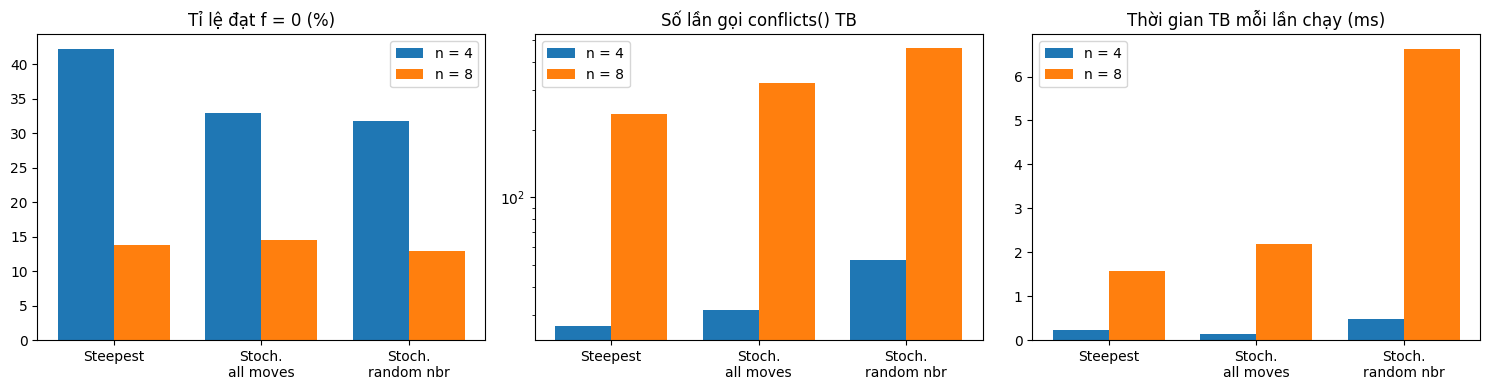

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
names = list(ALGOS)
x = np.arange(len(names)); w = 0.38
for k, n in enumerate((4, 8)):
    d = summary[summary.n == n].set_index("Thuật toán").loc[names]
    ax[0].bar(x + (k - 0.5) * w, d["Tỉ lệ thành công (%)"], w, label=f"n = {n}")
    ax[1].bar(x + (k - 0.5) * w, d["Số lần gọi f TB"], w, label=f"n = {n}")
    ax[2].bar(x + (k - 0.5) * w, d["Thời gian TB (ms)"], w, label=f"n = {n}")
for a, t in zip(ax, ["Tỉ lệ đạt f = 0 (%)", "Số lần gọi conflicts() TB", "Thời gian TB mỗi lần chạy (ms)"]):
    a.set_xticks(x); a.set_xticklabels(["Steepest", "Stoch.\nall moves", "Stoch.\nrandom nbr"])
    a.set_title(t); a.legend()
ax[1].set_yscale("log")
plt.tight_layout(); plt.show()


### Nhận xét (số liệu từ bảng trên, 1000 lần chạy mỗi ô)

* **Chất lượng nghiệm.** Với $n=4$ Steepest-ascent đạt $f=0$ ở khoảng 42% số lần, cao hơn rõ rệt so với hai biến thể ngẫu nhiên (khoảng 32-33%), chênh lệch lớn hơn sai số chuẩn (khoảng 1.5 điểm %). Với $n=8$ cả ba thuật toán chỉ thành công khoảng 13-15% và sự khác biệt nằm trong sai số (khoảng 1.1 điểm %). Điều này khớp với việc cả ba đều là thuật toán *leo đồi thuần túy* nên bị kẹt ở cực trị cục bộ ($f$ trung bình còn 1.2-1.3 ở $n=8$).
* **Chi phí tính toán.** Stochastic (random neighbor) dùng gần gấp đôi số lần gọi `conflicts()` so với Steepest-ascent ở $n=8$ (khoảng 460 so với 234), vì phải trả chi phí 'chứng minh' rằng không còn nước cải thiện bằng ngưỡng $x$ lần thử thất bại. Lợi thế của biến thể này chỉ xuất hiện khi số lân cận rất lớn so với ngưỡng cần thiết (xem câu hỏi thảo luận 3).
* **Thời gian.** Số lần gọi hàm mục tiêu không tỉ lệ hoàn toàn với thời gian: biến thể random neighbor chậm hơn nhiều so với tỉ lệ số lần gọi do mỗi lần thử còn tốn thêm các lệnh sinh số ngẫu nhiên của NumPy trong Python thuần.


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [13]:
import math, time
import pandas as pd

# Các phiên bản Hill Climbing (Task 1-3) có ghi lại lịch sử để vẽ đường hội tụ.
# Mỗi hàm nhận bàn cờ ban đầu và trả về (bàn cờ cuối, số xung đột cuối, history),
# trong đó history[k] = số xung đột sau vòng lặp thứ k.
# ---- Các biến thể HC (history = số xung đột sau mỗi vòng lặp) ----
def steepest_hc(board):
    b=np.array(board); f=conflicts(b); hist=[f]; n=len(b)
    while f>0:
        best=f; cands=[]
        for c in range(n):
            old=b[c]
            for r in range(n):
                if r==old: continue
                b[c]=r; fn=conflicts(b)
                if fn<best: best=fn; cands=[(c,r)]
                elif fn==best and cands: cands.append((c,r))
            b[c]=old
        if best>=f: break
        c,r=cands[0]; b[c]=r; f=best; hist.append(f)
    return b,f,hist

def ineff_stochastic_hc(board):
    b=np.array(board); f=conflicts(b); hist=[f]; n=len(b)
    while f>0:
        ups=[]
        for c in range(n):
            old=b[c]
            for r in range(n):
                if r==old: continue
                b[c]=r; fn=conflicts(b)
                if fn<f: ups.append((c,r,fn))
            b[c]=old
        if not ups: break
        c,r,fn=ups[np.random.randint(len(ups))]; b[c]=r; f=fn; hist.append(f)
    return b,f,hist

def efficient_stochastic_hc(board, patience=None):
    b=np.array(board); n=len(b); f=conflicts(b); hist=[f]
    m=n*(n-1)
    if patience is None: patience=int(math.ceil(m*math.log(max(m,2))))  # số lần thử không cải thiện tối đa (bài toán coupon collector: thử gần hết n(n-1) lân cận)
    fails=0
    while f>0 and fails<patience:
        c=np.random.randint(n); r=np.random.randint(n-1)
        if r>=b[c]: r+=1
        old=b[c]; b[c]=r; fn=conflicts(b)
        if fn<f: f=fn; fails=0
        else: b[c]=old; fails+=1
        hist.append(f)
    return b,f,hist

def random_restart(algo, n, max_restarts=100, **kw):
    """Chạy `algo` từ các bàn cờ ngẫu nhiên mới cho đến khi conflicts == 0 hoặc hết max_restarts lần.
    Trả về (bàn cờ tốt nhất, f tốt nhất, số lần khởi động đã dùng)."""
    best_b, best_f, used = None, float("inf"), 0
    for k in range(max_restarts):
        b, f, _ = algo(random_board(n), **kw)
        used = k + 1
        if f < best_f: best_b, best_f = b, f
        if f == 0: break
    return best_b, best_f, used


**Ghi chú cài đặt (Task 4).**

* Điều kiện dừng thống nhất cho mọi biến thể: dừng khi `conflicts == 0`, hoặc khi biến thể đó gặp cực trị cục bộ.
* *Ngân sách khởi động lại:* tối đa 100 lần; lưu lại giá trị f tốt nhất và số lần khởi động đã dùng.
* *Thiết lập nhất quán:* dùng `np.random.seed(1234)`, cùng ngân sách restart và cùng điều kiện dừng cho cả ba biến thể.
* Lặp lại toàn bộ quy trình random restart 100 lần cho mỗi biến thể và mỗi kích thước bàn cờ để ước tính xác suất tìm được bàn cờ không xung đột (n = 4 và 8).

In [14]:
np.random.seed(1234)
variants = {"Steepest asc. HC": steepest_hc,
            "Ineff. Stochastic HC": ineff_stochastic_hc,
            "Efficient Stochastic HC": efficient_stochastic_hc}
rows = []
for n in (4, 8):
    for name, algo in variants.items():
        res = [random_restart(algo, n, 100) for _ in range(100)]
        best_f = np.array([r[1] for r in res]); used = np.array([r[2] for r in res])
        rows.append({"Thuật toán": name, "n": n,
                     "f tốt nhất (TB)": best_f.mean(),
                     "Số restart TB": used.mean(),
                     "Số restart tối đa": used.max(),
                     "% lần đạt f=0": 100*np.mean(best_f == 0)})
rr_table = pd.DataFrame(rows)
rr_table.round(2)

,Thuật toán,n,f tốt nhất (TB),Số restart TB,Số restart tối đa,% lần đạt f=0
0,Steepest asc. HC,4,0.0,2.16,7,100.0
1,Ineff. Stochastic HC,4,0.0,3.21,18,100.0
2,Efficient Stochastic HC,4,0.0,3.31,20,100.0
3,Steepest asc. HC,8,0.0,7.02,25,100.0
4,Ineff. Stochastic HC,8,0.0,8.32,49,100.0
5,Efficient Stochastic HC,8,0.0,7.07,39,100.0


In [15]:
import time
_conf_orig = conflicts
_calls = 0
def _conf_counted(b):
    global _calls
    _calls += 1
    return _conf_orig(b)

def rr_run(algo, n, max_restarts=100):
    best_f, used, iters = float("inf"), 0, 0
    for k in range(max_restarts):
        b, f, h = algo(random_board(n))
        used, iters = k + 1, iters + len(h) - 1
        best_f = min(best_f, f)
        if f == 0: break
    return best_f, used, iters

def measure(name, fn, n, reps=100):
    global conflicts, _calls
    np.random.seed(1234); t0 = time.perf_counter()
    for _ in range(reps): fn(n)
    ms = (time.perf_counter() - t0) * 1000 / reps
    conflicts = _conf_counted; _calls = 0
    np.random.seed(1234)
    try:
        res = [fn(n) for _ in range(reps)]
    finally:
        conflicts = _conf_orig
    return {"Thuật toán": name, "n": n, "f cuối TB": np.mean([r[0] for r in res]),
            "% f=0": 100*np.mean([r[0] == 0 for r in res]),
            "Số restart TB": np.mean([r[1] for r in res]),
            "Số vòng lặp TB": np.mean([r[2] for r in res]),
            "Số lần gọi conflicts() TB": _calls/reps, "Thời gian TB (ms)": ms}

rr_algos = {"Steepest + RR": steepest_hc, "Ineff. Stochastic + RR": ineff_stochastic_hc,
            "Efficient Stochastic + RR": efficient_stochastic_hc}
rows = [measure(nm, lambda n, a=a: rr_run(a, n), n) for n in (4, 8) for nm, a in rr_algos.items()]
pd.DataFrame(rows).round(2)

,Thuật toán,n,f cuối TB,% f=0,Số restart TB,Số vòng lặp TB,Số lần gọi conflicts() TB,Thời gian TB (ms)
0,Steepest + RR,4,0.0,100.0,2.16,3.43,57.24,0.43
1,Ineff. Stochastic + RR,4,0.0,100.0,2.74,5.14,85.30,0.42
2,Efficient Stochastic + RR,4,0.0,100.0,3.41,103.54,106.95,1.14
3,Steepest + RR,8,0.0,100.0,7.06,22.75,1620.42,12.80
4,Ineff. Stochastic + RR,8,0.0,100.0,6.71,33.44,2199.11,19.39
5,Efficient Stochastic + RR,8,0.0,100.0,7.79,2036.05,2043.84,28.06


**Nhận xét (Task 4).** Một lần chạy hill climbing đơn lẻ chỉ giải được 8-Queens khoảng 10-15% số lần. Với random restart, cả ba biến thể đều đạt f = 0 trong 100% số lần lặp, trung bình cần khoảng 7-8 lần khởi động với n = 8 (và 2-3 lần với n = 4). Vì một lần chạy thành công với xác suất $p \approx 0.1$ nên số lần restart kỳ vọng là $1/p \approx 8-10$, khớp với bảng. Ba biến thể cần số restart gần như nhau, nên khác biệt thực sự nằm ở chi phí mỗi lần restart (steepest và inefficient stochastic đánh giá toàn bộ $n(n-1)$ lân cận ở mỗi bước, còn efficient stochastic chỉ đánh giá một lân cận).

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

Board with 0 conflicts.


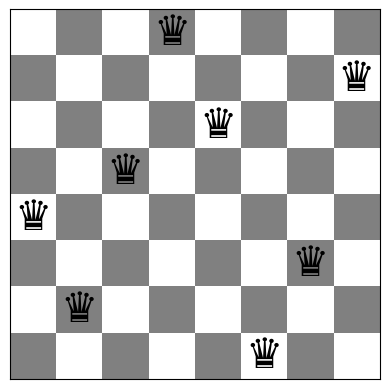

In [16]:
def simulated_annealing(board, T0=2.0, alpha=0.995, T_min=1e-3, max_iter=20000):
    """Simulated annealing với lịch làm nguội nhân: T <- alpha * T.
    Một nước đi ngẫu nhiên (đổi hàng của một quân hậu) luôn được chấp nhận nếu f không tăng;
    ngược lại được chấp nhận với xác suất exp(-delta / T). Dừng khi f == 0, T < T_min hoặc hết max_iter vòng lặp."""
    b = np.array(board); n = len(b); f = conflicts(b); hist = [f]; T = T0
    for _ in range(max_iter):
        if f == 0 or T < T_min: break
        c = np.random.randint(n); r = np.random.randint(n - 1)
        if r >= b[c]: r += 1                       # chọn một hàng khác trong cột c
        old = b[c]; b[c] = r; fn = conflicts(b); d = fn - f
        if d <= 0 or np.random.rand() < math.exp(-d / T): f = fn   # chấp nhận
        else: b[c] = old                                              # từ chối
        hist.append(f); T *= alpha
    return b, f, hist

np.random.seed(1234)
b, f, hist = simulated_annealing(random_board(8))
show_board(b, fontsize=30)

### Khảo sát lịch làm nguội (n = 8)

Giữ cố định seed, ngân sách vòng lặp (`max_iter = 20000`) và điều kiện dừng; thay đổi nhiệt độ đầu $T_0$ và tốc độ làm nguội $\alpha$. Với mỗi cấu hình: đồ thị là đường số xung đột của một lần chạy từ cùng một bàn cờ ban đầu, bảng bên dưới là tỉ lệ thành công trên 100 lần chạy.

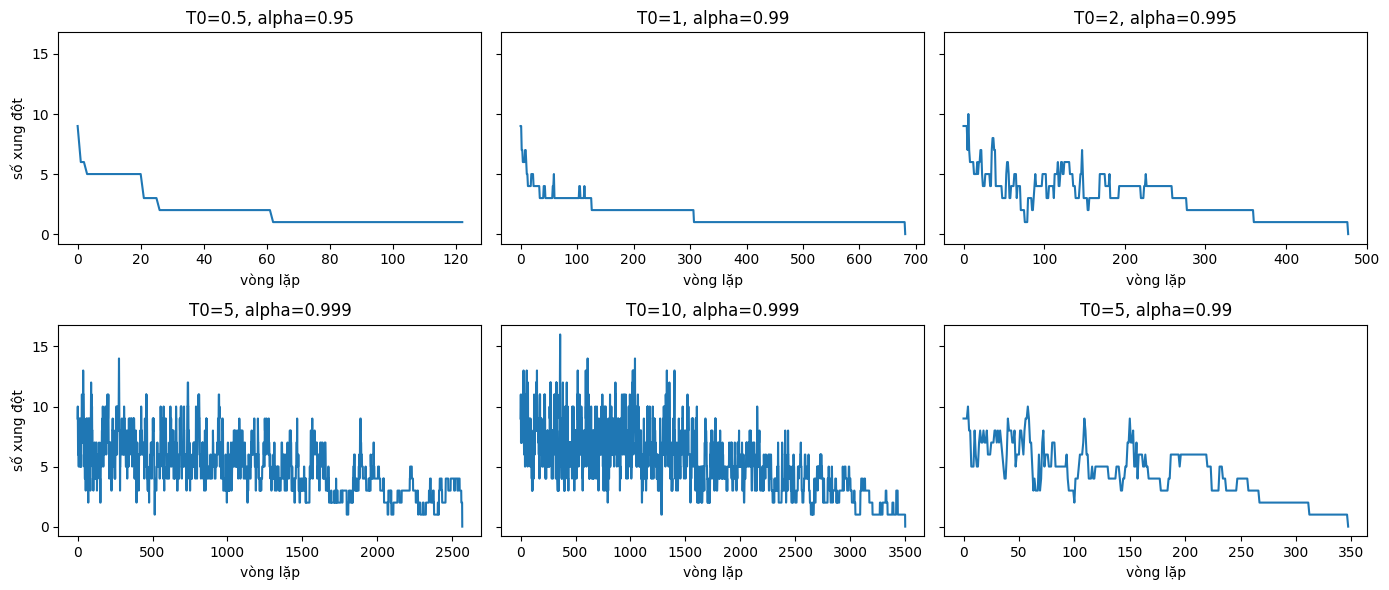

,T0,alpha,% thành công,f cuối (TB),số vòng lặp (TB)
0,0.5,0.950,15.0,1.10,118.0
1,1.0,0.990,66.0,0.34,463.0
2,2.0,0.995,84.0,0.16,730.0
3,5.0,0.999,100.0,0.00,2679.0
4,10.0,0.999,100.0,0.00,3102.0
5,5.0,0.990,64.0,0.36,588.0


In [17]:
settings = [(0.5, 0.95), (1, 0.99), (2, 0.995), (5, 0.999), (10, 0.999), (5, 0.99)]
np.random.seed(1234)
start = random_board(8)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
stats = []
for ax, (T0, a) in zip(axes.ravel(), settings):
    _, _, h = simulated_annealing(start, T0=T0, alpha=a)
    ax.plot(h); ax.set_title(f"T0={T0}, alpha={a}"); ax.set_xlabel("vòng lặp")
    runs = [simulated_annealing(random_board(8), T0=T0, alpha=a) for _ in range(100)]
    stats.append({"T0": T0, "alpha": a, "% thành công": 100*np.mean([r[1]==0 for r in runs]),
                  "f cuối (TB)": np.mean([r[1] for r in runs]), "số vòng lặp (TB)": np.mean([len(r[2]) for r in runs])})
axes[0,0].set_ylabel("số xung đột"); axes[1,0].set_ylabel("số xung đột")
plt.tight_layout(); plt.show()
pd.DataFrame(stats).round({"T0": 2, "alpha": 3, "% thành công": 1, "f cuối (TB)": 2, "số vòng lặp (TB)": 0})

In [18]:
# Tỉ lệ thành công của lịch được chọn (T0 = 5, alpha = 0.999) qua 100 lần chạy lặp lại với n = 4 và n = 8
np.random.seed(1234)
sa_rate = {n: np.mean([simulated_annealing(random_board(n), T0=5, alpha=0.999)[1] == 0 for _ in range(100)]) for n in (4, 8)}
pd.Series(sa_rate, name="Tỉ lệ thành công của SA").rename_axis("n")

n
4    1.0
8    1.0
Name: Tỉ lệ thành công của SA, dtype: float64

In [19]:
def sa_run(n):
    b, f, h = simulated_annealing(random_board(n), T0=5, alpha=0.999)
    return f, 1, len(h) - 1

rows = [measure("Simulated Annealing", sa_run, n) for n in (4, 8)]
pd.DataFrame(rows).round(2)

,Thuật toán,n,f cuối TB,% f=0,Số restart TB,Số vòng lặp TB,Số lần gọi conflicts() TB,Thời gian TB (ms)
0,Simulated Annealing,4,0.0,100.0,1.0,97.60,98.60,1.25
1,Simulated Annealing,8,0.0,100.0,1.0,2535.16,2536.16,35.65


**Nhận xét (Task 5).**

* *Nhiệt độ thấp / làm nguội quá nhanh* ($T_0 = 0.5$, $\alpha = 0.95$): nhiệt độ giảm xuống dưới $T_{min}$ chỉ sau khoảng 100 vòng lặp, SA khi đó hoạt động giống hill climbing thường và bị kẹt (chỉ thành công khoảng 15%).
* *$T_0$ lớn hơn và làm nguội chậm hơn* ($\alpha$ gần 1): lúc đầu đường cong dao động mạnh (chấp nhận nhiều bước xấu), sau đó giảm dần và phẳng lại khi $T \to 0$. Tỉ lệ thành công đạt khoảng 100% với $T_0 \ge 5$, $\alpha = 0.999$.
* *Đánh đổi:* lịch chậm hơn tốn nhiều vòng lặp hơn (khoảng 2.700-3.100 so với khoảng 100-700). $\alpha$ quan trọng hơn $T_0$: cặp ($T_0 = 5$, $\alpha = 0.99$) kém hơn rõ rệt so với ($T_0 = 5$, $\alpha = 0.999$).
* Ở Task 6, ta dùng $T_0 = 5$, $\alpha = 0.999$ cho mọi kích thước bàn cờ (số liệu có thể lệch nhẹ giữa các lần chạy do tính ngẫu nhiên).
* Lưu ý: cài đặt của ta chấp nhận cả bước có $\Delta = 0$ (đi ngang), còn đề chỉ nêu $\Delta < 0$ là luôn chấp nhận; sự khác biệt này giúp SA thoát khỏi vùng bằng phẳng (plateau).

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [20]:
algos6 = {"Steepest asc. HC": steepest_hc,
          "Ineff. Stochastic HC": ineff_stochastic_hc,
          "Efficient Stochastic HC": efficient_stochastic_hc,
          "Simulated Annealing": lambda b: simulated_annealing(b, T0=5, alpha=0.999)}

def benchmark(algo, n, runs=100):
    """Chạy `algo` từ `runs` bàn cờ ngẫu nhiên khác nhau; trả về thời gian TB (giây), số xung đột TB, % lần đạt nghiệm tối ưu."""
    times, fs = [], []
    for _ in range(runs):
        b0 = random_board(n)
        t = time.perf_counter(); _, f, _ = algo(b0); times.append(time.perf_counter() - t); fs.append(f)
    return np.mean(times), np.mean(fs), 100*np.mean(np.array(fs) == 0)

np.random.seed(1234)
rows = []
for n in (4, 8):
    for name, algo in algos6.items():
        t, f, s = benchmark(algo, n, 100)
        rows.append({"Thuật toán": name, "Kích thước bàn cờ": n, "Thời gian chạy TB (ms)": 1000*t,
                     "Số xung đột TB": f, "% lần đạt nghiệm tối ưu": s})
comparison = pd.DataFrame(rows)
comparison.round(3)

,Thuật toán,Kích thước bàn cờ,Thời gian chạy TB (ms),Số xung đột TB,% lần đạt nghiệm tối ưu
0,Steepest asc. HC,4,0.172,0.54,48.0
1,Ineff. Stochastic HC,4,0.193,0.76,35.0
2,Efficient Stochastic HC,4,0.232,0.90,26.0
3,Simulated Annealing,4,0.686,0.00,100.0
4,Steepest asc. HC,8,1.553,1.36,9.0
5,Ineff. Stochastic HC,8,2.526,1.27,13.0
6,Efficient Stochastic HC,8,3.176,1.44,9.0
7,Simulated Annealing,8,32.542,0.00,100.0


**Quan sát (bảng so sánh).** Các biến thể hill climbing thường kết thúc ở cực trị cục bộ trong phần lớn số lần chạy trên 8-Queens (chỉ khoảng 10% đạt f = 0, f trung bình khoảng 1,3-1,4) và chất lượng của ba biến thể gần như tương đương. Simulated annealing đạt f = 0 trong 100% số lần chạy với n = 4 và 8, nhưng chậm hơn trên mỗi lần chạy (khoảng 10-20 lần với n = 8) vì phải thực hiện rất nhiều vòng lặp nhẹ. Steepest-ascent chạy nhanh nhất mỗi lần nhưng cũng thất bại nhiều nhất; random restart (Task 4) khắc phục điều này với chi phí thấp.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

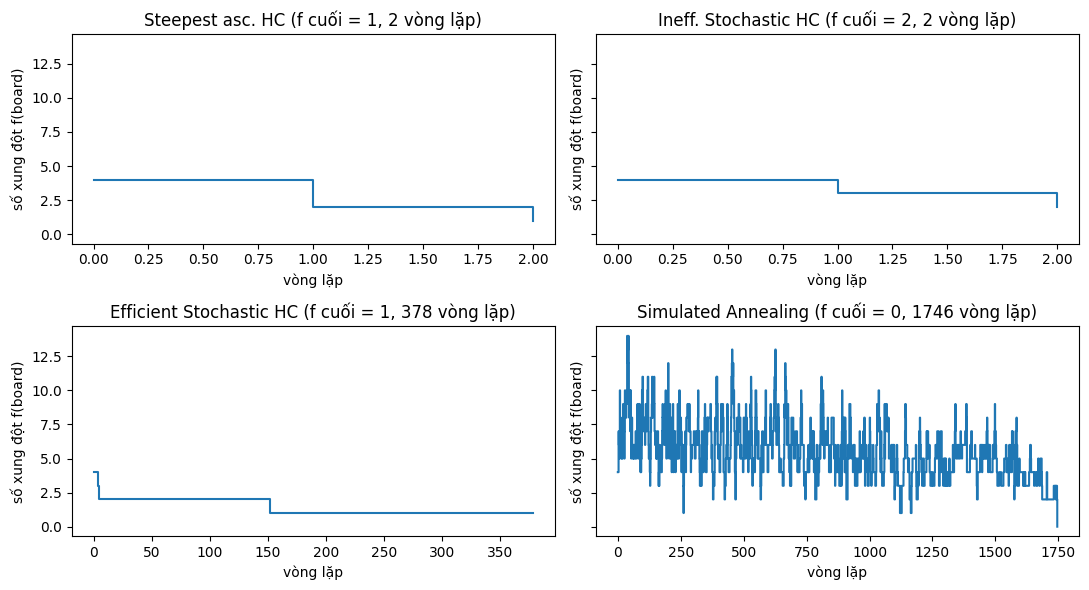

Steepest asc. HC           0.86
Ineff. Stochastic HC       0.86
Efficient Stochastic HC    0.84
Simulated Annealing        0.00
Name: tỉ lệ lần chạy bị kẹt (n=8), dtype: float64

In [21]:
# Tìm một bàn cờ ban đầu (cố định theo seed) mà cả ba biến thể HC đều bị kẹt (f > 0).
# Khoảng 85% lần chạy HC bị kẹt nên đây là trường hợp điển hình; SA chạy từ cùng bàn cờ đó.
hc_names = list(algos6)[:3]
for seed in range(7, 300):
    np.random.seed(seed); start = random_board(8)
    results = {}
    for name, algo in algos6.items():
        np.random.seed(seed); results[name] = algo(start)
    if all(results[nm][1] > 0 for nm in hc_names): break

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for ax, (name, (_, f, h)) in zip(axes.ravel(), results.items()):
    ax.step(range(len(h)), h, where="post"); ax.set_title(f"{name} (f cuối = {f}, {len(h)-1} vòng lặp)")
    ax.set_xlabel("vòng lặp"); ax.set_ylabel("số xung đột f(board)")
plt.tight_layout(); plt.show()

# Tỉ lệ lần chạy (n=8) bị kẹt ở cực trị cục bộ (f > 0)
np.random.seed(1234)
stuck = {name: np.mean([algo(random_board(8))[1] > 0 for _ in range(200)]) for name, algo in algos6.items()}
pd.Series(stuck, name="tỉ lệ lần chạy bị kẹt (n=8)").round(2)

**Các dạng hội tụ.** (Hình minh họa một bàn cờ ban đầu mà cả ba biến thể hill climbing đều bị kẹt, vì khoảng 85% lần chạy trên 8-Queens kết thúc như vậy.)

* *Steepest-ascent / inefficient stochastic HC:* cải thiện ban đầu rất nhanh (chỉ vài bước), sau đó đường cong đi ngang ở f > 0: thuật toán dừng ở cực trị cục bộ (khoảng 86% số lần chạy). Biến thể inefficient đi từng bước nhỏ hơn vì chọn ngẫu nhiên một bước cải thiện thay vì bước tốt nhất, nhưng cũng dừng ở cùng kiểu cực trị.
* *Efficient stochastic HC:* có những đoạn đi ngang dài (đa số lân cận được sinh ra đều bị từ chối) xen kẽ các lần giảm đột ngột. Thuật toán dừng khi hết số lần thử không cải thiện, nên đoạn đi ngang chính là thời gian chờ một bước cải thiện; khoảng 84% số lần chạy bị kẹt ở cực trị cục bộ.
* *Simulated annealing:* lúc đầu dao động mạnh (chấp nhận bước xấu, f có thể tăng lên rất cao), sau đó giảm dần về 0 khi nhiệt độ hạ; với lịch đã chọn, đây là thuật toán duy nhất không bị kẹt trong 200 lần chạy trên n = 8.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

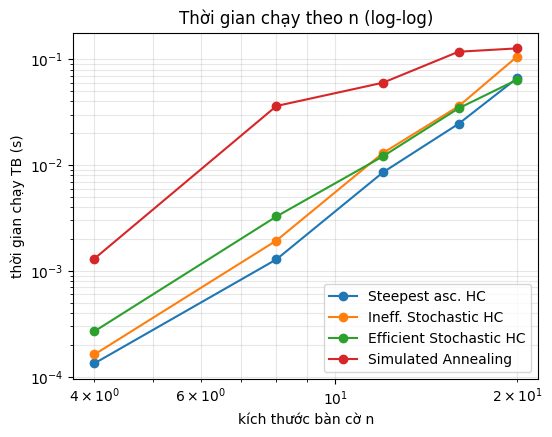

,số mũ thực nghiệm k
Steepest asc. HC,3.88
Ineff. Stochastic HC,4.03
Efficient Stochastic HC,3.42
Simulated Annealing,2.83


In [22]:
sizes = [4, 8, 12, 16, 20]
reps = 30
np.random.seed(1234)
scal = {name: [] for name in algos6}
for n in sizes:
    for name, algo in algos6.items():
        scal[name].append(benchmark(algo, n, reps)[0])

plt.figure(figsize=(6, 4.5))
for name, ts in scal.items():
    plt.loglog(sizes, ts, "o-", label=name)
plt.xlabel("kích thước bàn cờ n"); plt.ylabel("thời gian chạy TB (s)"); plt.grid(True, which="both", alpha=.3)
plt.legend(); plt.title("Thời gian chạy theo n (log-log)"); plt.show()

# ước lượng số mũ thực nghiệm k trong  thời gian ~ n^k  bằng hồi quy tuyến tính trong không gian log-log
slopes = {name: np.polyfit(np.log(sizes), np.log(ts), 1)[0] for name, ts in scal.items()}
pd.DataFrame({"số mũ thực nghiệm k": slopes}).round(2)

In [23]:
# Tỉ lệ thành công trong thí nghiệm mở rộng (cùng một lịch làm nguội cho mọi n) - cần để diễn giải thời gian chạy
np.random.seed(1234)
succ = {name: [benchmark(algo, n, 30)[2] for n in sizes] for name, algo in algos6.items()}
pd.DataFrame(succ, index=[f"n={n}" for n in sizes]).T.round(0)

,n=4,n=8,n=12,n=16,n=20
Steepest asc. HC,53.0,7.0,3.0,3.0,0.0
Ineff. Stochastic HC,43.0,7.0,0.0,0.0,0.0
Efficient Stochastic HC,40.0,17.0,3.0,3.0,0.0
Simulated Annealing,100.0,100.0,93.0,83.0,80.0


**Nhận xét (khả năng mở rộng).** Độ dốc ước lượng trên đồ thị log-log là $k \approx 3,9$ với steepest-ascent, $k \approx 4,1$ với inefficient stochastic HC, $k \approx 3,3$ với efficient stochastic HC và $k \approx 3,0$ với SA. Điều này phù hợp với chi phí mỗi bước: hàm `conflicts()` của ta có độ phức tạp $O(n)$ và có $n(n-1)$ lân cận, nên một bước steepest-ascent hay inefficient stochastic tốn khoảng $O(n^3)$ và số bước cũng tăng theo $n$ (tổng cỡ $O(n^4)$); trong khi một bước của efficient stochastic HC hay SA chỉ tốn $O(n)$.

*Lưu ý với SA:* đường thời gian của SA tăng mạnh từ n = 4 lên n = 8 rồi phẳng dần, vì lịch làm nguội cố định ($T_0 = 5$, $\alpha = 0.999$ cho tối đa khoảng 8.500 vòng lặp), nên thời gian bị chặn bởi ngân sách thay vì tăng theo $n$. Hệ quả là SA hết ngân sách với $n$ lớn: bảng tỉ lệ thành công ở trên cho thấy SA giảm xuống còn khoảng 93% với n = 12, 83% với n = 16 và 80% với n = 20. Để giữ tỉ lệ thành công không đổi cần tăng $\alpha$ theo $n$, và khi đó thời gian chạy sẽ tăng nhanh hơn so với những gì hiển thị ở đây. Efficient stochastic HC (không restart) gần như không bao giờ tìm được f = 0 khi $n \ge 12$ (0-3% số lần chạy), nên thời gian của nó chỉ đo thời gian để bị kẹt. Mỗi ô chỉ dựa trên 30 lần chạy nên tỉ lệ thành công có sai số khá lớn (mỗi lần chạy tương đương 3,3 điểm phần trăm).

**Kết luận:** trong các biến thể không dùng restart, chỉ SA giải được bàn cờ lớn một cách tương đối đáng tin cậy; xét theo chi phí mỗi bước, efficient stochastic HC và SA mở rộng tốt nhất (khoảng $O(n^3)$ trong các phép đo của ta; ước lượng này chỉ mang tính tương đối vì chỉ có 5 kích thước và 30 lần chạy).

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

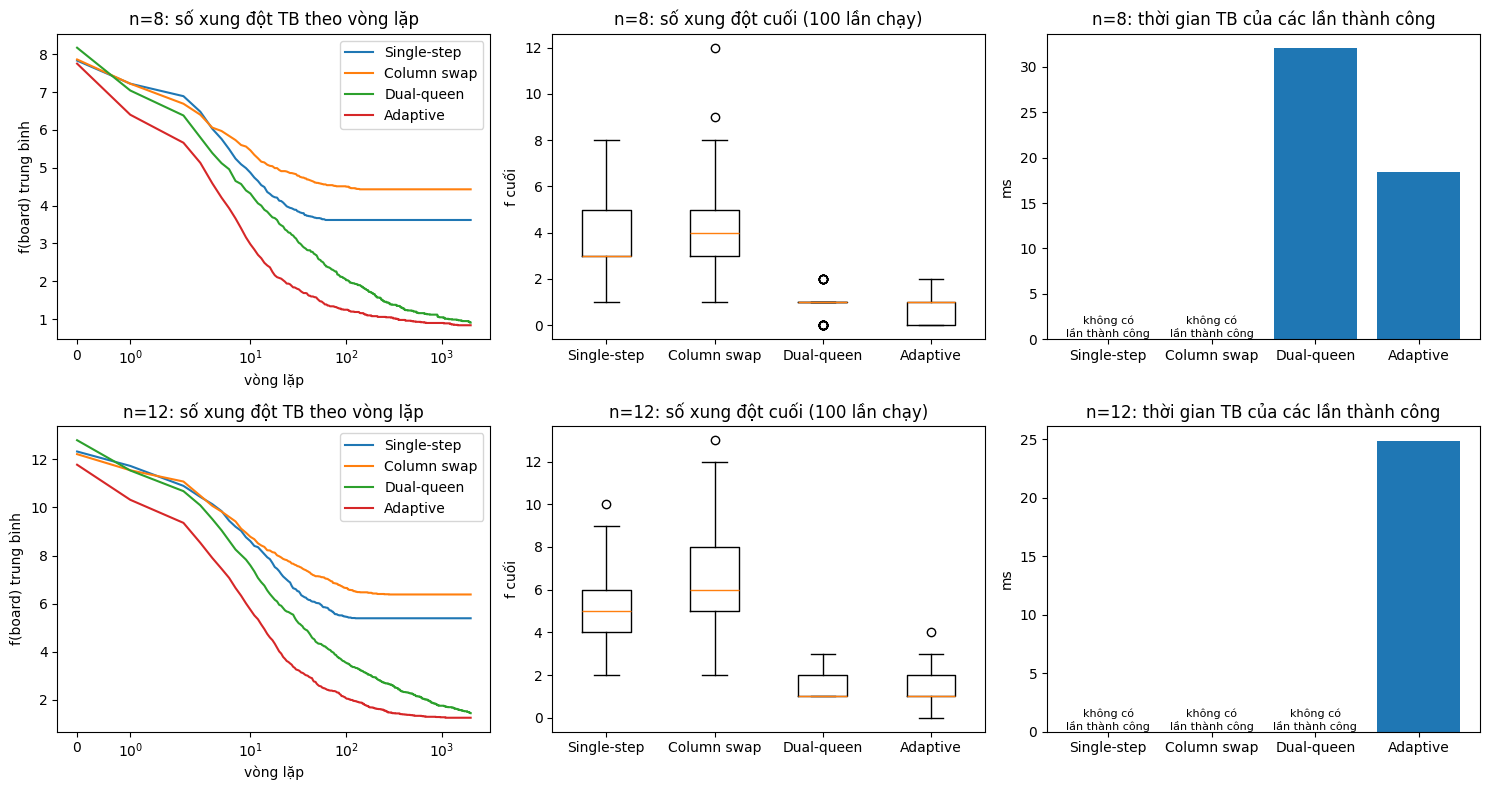

,n,Toán tử,% thành công (f=0),f cuối (TB),thời gian TB lần thành công (ms)
0,8,Single-step,0.0,3.62,NaN
1,8,Column swap,0.0,4.43,NaN
2,8,Dual-queen,17.0,0.91,32.04
3,8,Adaptive,35.0,0.84,18.41
4,12,Single-step,0.0,5.39,NaN
5,12,Column swap,0.0,6.38,NaN
6,12,Dual-queen,0.0,1.44,NaN
7,12,Adaptive,15.0,1.25,24.86


In [24]:
# ---------- Các toán tử di chuyển: mỗi toán tử nhận một bàn cờ và trả về một bàn cờ lân cận MỚI ----------
def queen_conflicts(b, i):
    """Số quân hậu đang tấn công quân hậu thứ i (cùng hàng hoặc cùng đường chéo)."""
    n = len(b); j = np.arange(n); j = j[j != i]
    return int(np.sum((b[j] == b[i]) | (np.abs(b[j] - b[i]) == np.abs(j - i))))

def move_single_step(b):
    """Di chuyển một quân hậu ngẫu nhiên đúng một ô lên hoặc xuống (không ra khỏi bàn cờ)."""
    n = len(b); nb = b.copy(); c = np.random.randint(n)
    step = np.random.choice([-1, 1])
    if not 0 <= nb[c] + step < n: step = -step
    nb[c] += step
    return nb

def move_column_swap(b):
    """Hoán đổi hàng của hai quân hậu ở hai cột được chọn ngẫu nhiên."""
    nb = b.copy(); c1, c2 = np.random.choice(len(b), 2, replace=False)
    nb[c1], nb[c2] = nb[c2], nb[c1]
    return nb

def move_dual_queen(b):
    """Chọn hai quân hậu và đồng thời chuyển cả hai sang các hàng mới ngẫu nhiên."""
    n = len(b); nb = b.copy()
    for c in np.random.choice(n, 2, replace=False):
        nb[c] = np.random.choice([r for r in range(n) if r != b[c]])
    return nb

def move_adaptive(b):
    """Toán tử thích nghi: với xác suất 0,5 đặt lại một trong các quân hậu bị xung đột nhiều nhất (nước đi tập trung);
    ngược lại chọn ngẫu nhiên một trong ba toán tử ở trên (khám phá)."""
    n = len(b)
    if np.random.rand() < 0.5:
        qc = np.array([queen_conflicts(b, i) for i in range(n)])
        c = np.random.choice(np.flatnonzero(qc == qc.max())); nb = b.copy()
        nb[c] = np.random.choice([r for r in range(n) if r != b[c]])
        return nb
    return np.random.choice([move_single_step, move_column_swap, move_dual_queen])(b)

operators = {"Single-step": move_single_step, "Column swap": move_column_swap,
             "Dual-queen": move_dual_queen, "Adaptive": move_adaptive}

def stochastic_hc_op(board, op, max_iter=2000):
    """Efficient stochastic HC (logic của Task 3): sinh MỘT lân cận bằng toán tử `op`,
    chỉ chấp nhận nếu có ít xung đột hơn. Dùng ngân sách cố định max_iter vòng lặp để mọi toán tử
    có cùng mức công sức. Trả về bàn cờ cuối, f cuối và lịch sử f."""
    b = np.array(board); f = conflicts(b); hist = [f]
    for _ in range(max_iter):
        if f == 0: break
        nb = op(b); fn = conflicts(nb)
        if fn < f: b, f = nb, fn
        hist.append(f)
    return b, f, hist

runs, max_iter = 100, 2000
adv = {}
np.random.seed(1234)
for n in (8, 12):
    for name, op in operators.items():
        H = np.zeros((runs, max_iter + 1)); finals = []; tsucc = []
        for r in range(runs):
            t = time.perf_counter(); _, f, h = stochastic_hc_op(random_board(n), op, max_iter)
            dt = time.perf_counter() - t
            H[r] = h + [h[-1]] * (max_iter + 1 - len(h))     # điền bằng giá trị cuối (lần chạy đã dừng ở f = 0 hoặc đã hết vòng lặp)
            finals.append(f)
            if f == 0: tsucc.append(dt)
        adv[(n, name)] = dict(H=H, finals=np.array(finals), tsucc=tsucc)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, n in enumerate((8, 12)):
    for name in operators:
        d = adv[(n, name)]; axes[row, 0].plot(d["H"].mean(axis=0), label=name)
    axes[row, 0].set_title(f"n={n}: số xung đột TB theo vòng lặp"); axes[row, 0].set_xlabel("vòng lặp")
    axes[row, 0].set_ylabel("f(board) trung bình"); axes[row, 0].set_xscale("symlog"); axes[row, 0].legend()
    axes[row, 1].boxplot([adv[(n, nm)]["finals"] for nm in operators]); axes[row, 1].set_xticklabels(list(operators))
    axes[row, 1].set_title(f"n={n}: số xung đột cuối (100 lần chạy)"); axes[row, 1].set_ylabel("f cuối")
    axes[row, 2].bar(list(operators), [1000*np.mean(adv[(n, nm)]["tsucc"]) if adv[(n, nm)]["tsucc"] else 0 for nm in operators])
    for k, nm in enumerate(operators):               # ghi chú các toán tử không có lần thành công nào
        if not adv[(n, nm)]["tsucc"]:
            axes[row, 2].text(k, 0, "không có\nlần thành công", ha="center", va="bottom", fontsize=8)
    axes[row, 2].set_title(f"n={n}: thời gian TB của các lần thành công"); axes[row, 2].set_ylabel("ms")
plt.tight_layout(); plt.show()

pd.DataFrame([{"n": n, "Toán tử": nm,
               "% thành công (f=0)": 100*np.mean(adv[(n, nm)]["finals"] == 0),
               "f cuối (TB)": adv[(n, nm)]["finals"].mean(),
               "thời gian TB lần thành công (ms)": 1000*np.mean(adv[(n, nm)]["tsucc"]) if adv[(n, nm)]["tsucc"] else np.nan}
              for n in (8, 12) for nm in operators]).round(2)

**Nhận xét (phần nâng cao).** Mọi toán tử đều được dùng trong cùng một efficient stochastic hill climbing (chỉ chấp nhận khi cải thiện hẳn, 2.000 vòng lặp, 100 lần chạy cho mỗi trường hợp, không restart).

* *Single-step* có lân cận rất nhỏ (2 nước đi cho mỗi quân hậu). Nó cải thiện được một chút nhưng bị kẹt rất nhanh (đường cong phẳng sau khoảng 100 vòng lặp): tỉ lệ thành công 0% với cả n = 8 và 12.
* *Column swap* chỉ hoán đổi hàng giữa hai cột, nên tập hợp các hàng đang có quân hậu không đổi: số cặp quân hậu cùng hàng luôn giữ nguyên, toán tử chỉ có thể sửa xung đột đường chéo. Nó chỉ đạt f = 0 nếu bàn cờ ban đầu đã là một hoán vị (không có hai quân cùng hàng), xác suất chỉ khoảng $n!/n^n \approx 0{,}2\%$ với n = 8. Vì vậy 0% thành công và f cuối trung bình cao nhất; toán tử này đứng một mình không hiệu quả (nhưng sẽ rất tốt nếu khởi tạo bằng hoán vị).
* *Dual-queen* có lân cận lớn hơn nhiều (khoảng $\binom{n}{2}(n-1)^2$ nước đi). Nó thoát được nhiều cực trị cục bộ hơn các nước đi một quân (thành công 17% với n = 8) nhưng không có lần thành công nào với n = 12 trong ngân sách đã cho, và tốn thời gian hơn vì nhiều đề xuất bị từ chối.
* *Adaptive* (50% tập trung vào quân hậu bị xung đột nhiều nhất, 50% chọn ngẫu nhiên một toán tử) hoạt động tốt nhất: tỉ lệ thành công cao nhất (35% với n = 8, 15% với n = 12), f cuối trung bình thấp nhất, và thời gian mỗi lần thành công ngắn hơn Dual-queen ở n = 8 (khoảng 16 ms so với 35 ms).

Hai toán tử Dual-queen và Adaptive vẫn còn đang giảm ở vòng lặp 2.000 nên kết quả của chúng bị giới hạn bởi ngân sách; tăng `max_iter` có thể cải thiện thêm.

**Kết luận:** kích thước lân cận quan trọng: lân cận quá nhỏ (single-step) thì bị kẹt, còn lân cận quá lớn hoặc không có định hướng thì lãng phí nhiều đề xuất. Tập trung vào các quân hậu đang xung đột là sự cân bằng tốt nhất, giống bài học với simulated annealing: cần cả khám phá lẫn định hướng. (Các phần trăm có thể lệch nhẹ giữa các lần chạy.)

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [25]:
# Code and description go here